---
format:
  html:
    code-fold: true
    embed-resources: true
---

# K-Nearest Neighbors and Decision Trees for Regression

Before we implement models using scikit-learn, let's think conceptually about the $k$-nearest neighbors and decision tree algorithms for regression.

In [3]:
import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

## Visualizing K-Nearest Neighbors Regression Functions

A predictive model is simply a function $f$ that maps feature values ${\bf x}$ to target values $y$. We can visualize $f$ when ${\bf x}$ consists of just a single feature. We have seen that a linear regression function $f$ based on a single feature $x$ is a linear function of $x$. What does $f$ look like when the model is a $k$-nearest neighbors regressor?


### K-Nearest Neighbors Regression Functions for a Single Quantitative Feature: Wine Data


Recall the wines data set where our target is log(price), a proxy for quality.
We'll use a K-Nearest Neighbors model for predicting log(price) from a single feature, age.

First, we extract the training data. There is no need to scale the features in this case because there is only one feature. (The point of scaling is to bring all of the *feature* variables to the same scale before computing distances between observations.)

In [4]:
bordeaux_df = pd.read_csv("https://dlsun.github.io/pods/data/bordeaux.csv",
                          index_col="year")

# Split the data into training and test sets
bordeaux_train = bordeaux_df.loc[:1980].copy()
bordeaux_test = bordeaux_df.loc[1981:].copy()

# Log transform the target
bordeaux_train["log(price)"] = np.log(bordeaux_train["price"])

# train on a single feature, age
X_train = bordeaux_train[["age"]]
y_train = bordeaux_train["log(price)"]

In [5]:
bordeaux_train[["age", "log(price)"]].sort_values("age").head(5)

,age,log(price)
year,,
1980,12,2.639057
1979,13,3.044522
1978,14,3.295837
1977,15,2.397895
1976,16,3.218876


Let's make a scatterplot of the training data. Careful! In the reading, we made several scatterplots where both the x-axis and y-axis corresponded to *feature* variables (and the target corresponded to color). But now the x-axis is the feature and the y-axis is the target.

<Axes: xlabel='age', ylabel='log(price)'>

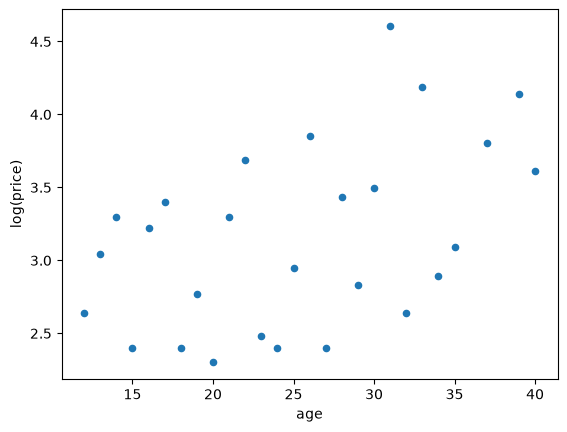

In [6]:
bordeaux_train.plot.scatter(x="age", y="log(price)")

1. Consider a **1-nearest neighbor** regression model. Say we want to add the regression function to the scatterplot. Sketch a plot of what the regression function would look like. **Discuss with your partner before proceeding.** Hint: The smallest ages in the training data are 12, 13, 14, etc. What would the predicted price be for age = 12? age = 13? age = 11.5? age = 12.49? age = 12.51? age = 13.49? age = 13.51?

It is a step function that predicts the log(price) of the nearest wine age. The prediction changes halfway between each pair of observed ages. 

2. Consider a **2-nearest neighbor** regression model. Say we want to add the regression function to the scatterplot. Sketch a plot of what the regression function would look like. **Discuss with your partner before proceeding.** Hint: The smallest ages in the training data are 12, 13, 14, etc. What would the predicted price be for age = 12? age = 12.99? age = 13.01? age = 13.99? age = 14.01?

This is also a step function, but each prediction is the average log(price) of the two closest wine ages. The steps change when the two nearest neighbors change. 

3. What would the 27-nearest neighbors regression function look like? **Discuss with your partner before proceeding.** Hint: what is special about 27 in this example?

With k = 27, every training ovbservation is used so the predicted log(price) is the overall mean log(price) for every age. The regression function is therefore a flat horizontal line. 

4. Now we'll fit a K-nearest neighbors regression model and plot the regression function for K=1, 2, 10, 27. The code below basically implements the code from the previous part for each of the values of K. Run the code and **discuss the output with your partner**. Do the regression functions look like what you expected? What happens as K increases?

<Axes: xlabel='age', ylabel='log(price)'>

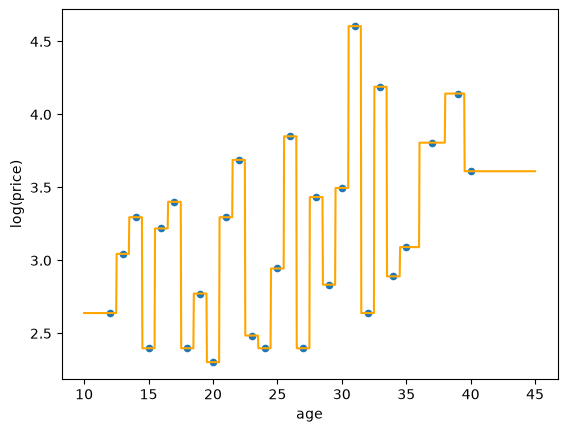

In [7]:
# 1-nearest neighbor model
from sklearn.neighbors import KNeighborsRegressor

# Fit k-nearest neighbors
model = KNeighborsRegressor(n_neighbors=1)
model.fit(X=X_train, y=y_train)

# Define a grid of feature values to make predictions for
X_new = pd.DataFrame()
X_new["age"] = np.linspace(10, 45, num=1000)

# Make predictions at those feature values.
y_new_ = pd.Series(
    # ADD YOUR CODE HERE,
    model.predict(X_new),
    index=X_new["age"]
)

# Plot the scatter plot and the predictions (regression function)
bordeaux_train.plot.scatter(x="age", y="log(price)")
y_new_.plot.line(color = "orange")


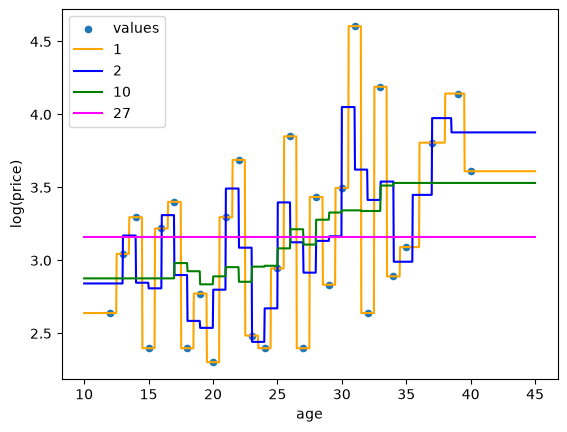

In [8]:
# k-nearest neighbors for several values of k
ks = [1, 2, 10, 27]
colors = ["orange", "blue", "green", "magenta", "black"]

bordeaux_train.plot.scatter(x="age", y="log(price)")

# Define a grid of feature values.
X_new = pd.DataFrame()
X_new["age"] = np.linspace(10, 45, num=1000)

for i in range(len(ks)):

  # Fit k-nearest neighbors
  model = KNeighborsRegressor(n_neighbors=ks[i])
  model.fit(X=X_train, y=y_train)

  # Make predictions at those feature values.
  y_new_ = pd.Series(
      model.predict(X_new),
      index=X_new["age"]
  )

  # Plot the predictions.
  y_new_.plot.line(color = colors[i])
  plt.legend(["values"] + ks);


The plots look like step functions. As k increases, the steps become smoother and less sensitive to individual wines; at k = 27, the prediction is a flat line at the overall mean log(price).

### K-Nearest Neighbors Regression Functions for a Single Categorical Feature: Housing Data

Recall the Ames housing data set. We'll use a single categorical feature---Neighborhood---to predict SalePrice.

In [9]:
df_ames = pd.read_csv("http://dlsun.github.io/pods/data/AmesHousing.txt", sep = "\t")

df_ames[["Neighborhood", "SalePrice"]]

,Neighborhood,SalePrice
0,NAmes,215000
1,NAmes,105000
2,NAmes,172000
3,NAmes,244000
4,Gilbert,189900
...,...,...
2925,Mitchel,142500
2926,Mitchel,131000
2927,Mitchel,132000
2928,Mitchel,170000


We'll fit a **10-nearest neighbors** regression model to predict house price using **Neighborhood** as the only feature. Since Neighborhood is categorical we first need to convert it to dummies, using a `ColumnTransformer` and a `Pipeline`.

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

X = df_ames[["Neighborhood"]]
y = df_ames["SalePrice"]

ct = ColumnTransformer(
    [("dummify", OneHotEncoder(), ["Neighborhood"])]
)

knn_model = Pipeline([
    ("preprocessing", ct),
    ("knn", KNeighborsRegressor(n_neighbors=10))
])

knn_model.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('knn', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](1,)",['Neighborhood']
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,1
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('dummify', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,ex

Now we'll find the predicted price for each Neighborhood.

In [11]:
neighborhoods = pd.Series(df_ames["Neighborhood"].unique(), name="Neighborhood").to_frame()
neighborhoods["predicted"] = knn_model.predict(neighborhoods)
neighborhoods

,Neighborhood,predicted
0,NAmes,142771.0
1,Gilbert,221722.5
2,StoneBr,300637.0
3,NWAmes,180795.0
4,Somerst,230960.0
5,BrDale,108850.0
6,NPkVill,140115.0
7,NridgHt,346588.3
8,Blmngtn,209917.9
9,NoRidge,325105.0


Let's compare the predicted prices to the mean price for each neighborhood.

In [13]:
pd.merge(pd.merge(neighborhoods,
                  df_ames.groupby("Neighborhood")["SalePrice"].mean(), left_on = "Neighborhood", right_index = True),
         df_ames["Neighborhood"].value_counts(), left_on = "Neighborhood", right_index = True).sort_values("count")

,Neighborhood,predicted,SalePrice,count
27,Landmrk,122920.0,137000.000000,1
26,GrnHill,150790.0,280000.000000,2
12,Greens,181175.0,193531.250000,8
21,Blueste,143590.0,143590.000000,10
6,NPkVill,140115.0,140710.869565,23
25,Veenker,254750.0,248314.583333,24
8,Blmngtn,209917.9,196661.678571,28
5,BrDale,108850.0,105608.333333,30
24,MeadowV,104390.0,95756.486486,37
16,ClearCr,222100.0,208662.090909,44


 5. For what neighborhood is the predicted price equal to the neighborhood's mean price? Why? What is special about that neighborhood? Can you explain why the predicted prices don't match the mean price for the other neighborhoods?

Blueste is the neighborhood where predicted price is equal to the mean price. It has exactly 10 houses, so all 10 nearest neighbors are houses in Blueste and the prediction equals its mean sale price. 
Other neighborhoods have more or fewer than 10 houses, so KNN either selects only some same-neighborhood houses or includes houses from other neighborhoods.

### K-Nearest Neighbors Regression Functions for Two Quantitative Features: Sketching for Small Training Data

When there are multiple features, a regression function will be a surface in a higher dimensional space and is therefore difficult to visualize. Essentially the regression function splits the feature space into regions based on which $K$ points in the training data are closest, and makes constant predictions over these regions so that the regression surface has something like a ["log step"](https://i.pinimg.com/originals/f3/61/21/f36121c84fa42b6cad525f865d61d049.png) shape.

We'll sketch plots of the regression surface when there are two quantitative features and the training data only contains a few observations. Assume that the features have already been scaled and that Euclidean distance is used to determine nearest neighbors.

6. Consider **1-nearest neighbors** regression model based on two quantitative features which have already been scaled. Imagine the training data set only contains 2 observations. Skecth a plot of the regression function.  **Discuss with your partner.**

**Sketch on paper and discuss with your partner.**
With only two observations, the feature space is split into two regions. Everything closer to point A gets A's outcome; everything closer to point B gets B's outcome. The boundary is the line exactly halfway between the two points. 

7. Consider **1-nearest neighbors** regression model based on two quantitative features which have already been scaled. Imagine the training data set only contains 3 observations. Skecth a plot of the regression function.  **Discuss with your partner.**

**Sketch on paper and discuss with your partner.** This time, the feature space would be split into three regions. Every point get the target value of the closest observation. 


8. Consider **2-nearest neighbors** regression model based on two quantitative features which have already been scaled. Imagine the training data set only contains 3 observations. Skecth a plot of the regression function.  **Discuss with your partner.**

**Sketch on paper and discuss with your partner.** Since it is 2 nearest neighbors, each point is predicted by averaging the target values of its two closest observations. With three observations, the feature space is split into three regions where the prediction is the average of the closer two obervations' target values. 

## Decision Trees

Back to the wine data. Suppose again that we want to predict log(price) based on just a single feature, age.

<Axes: xlabel='age', ylabel='log(price)'>

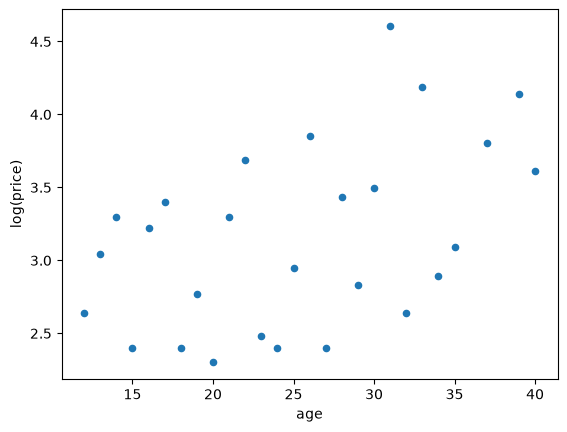

In [14]:
bordeaux_train.plot.scatter(x="age", y="log(price)")

9. Suppose we use a regression decision tree with a single split at 20.5. Sketch a plot of what the regression function would look like.

**Sketch on paper and discuss with your partner.** A vertical split at age 20.5 and one horizontal prediction line on each side. For age less than or equal to 20.5, prefict mean log(price) of all wines in that group and do the same for age greater than 20.5.

10. Suppose we use a decision tree with two splits at 20.5 and 30.5. Sketch a plot of what the regression function would look like.

**Sketch on paper and discuss with your partner.** Draw vertical splits at 20.5 and 30.5 and create three aage ranges to predict mean(log) price. 

## Fitting KNN Regression Models with scikit-learn: Housing data

11. Fit a 10-nearest neighbors regression model that predicts the price (just **SalePrice**, not log) of a home using square footage (**Gr Liv Area**), number of bedrooms (**Bedroom AbvGr**), number of full bathrooms (**Full Bath**), number of half bathrooms (**Half Bath**), and **Neighborhood**. Use a pipeline and column transformers as needed. Make a scatter plot of predicting price versus actual price.

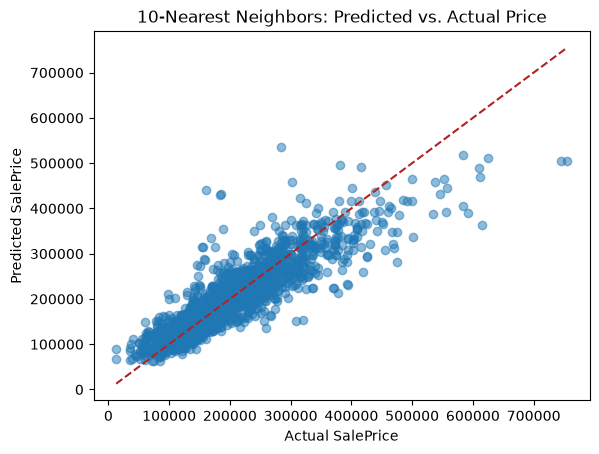

In [15]:
from sklearn.preprocessing import StandardScaler

features = ["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath", "Neighborhood"]
numeric_features = ["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath"]
categorical_features = ["Neighborhood"]

X = df_ames[features]
y = df_ames["SalePrice"]

preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_features),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

knn_10 = Pipeline([
    ("preprocessing", preprocessor),
    ("knn", KNeighborsRegressor(n_neighbors=10))
])

knn_10.fit(X, y)
predicted_price = knn_10.predict(X)

plt.scatter(y, predicted_price, alpha=0.5)
limits = [min(y.min(), predicted_price.min()), max(y.max(), predicted_price.max())]
plt.plot(limits, limits, color="firebrick", linestyle="--")
plt.xlabel("Actual SalePrice")
plt.ylabel("Predicted SalePrice")
plt.title("10-Nearest Neighbors: Predicted vs. Actual Price")
plt.show()

12. Repeat the previous part to fit a $k$-nearest neighbors model for some other value of $k$. Experiment with different values of $k$. (For this, you can just pick and choose a few, no need to automate it. We'll see how to do that later.) What value of $k$ seems to be "best"? How are you deciding?

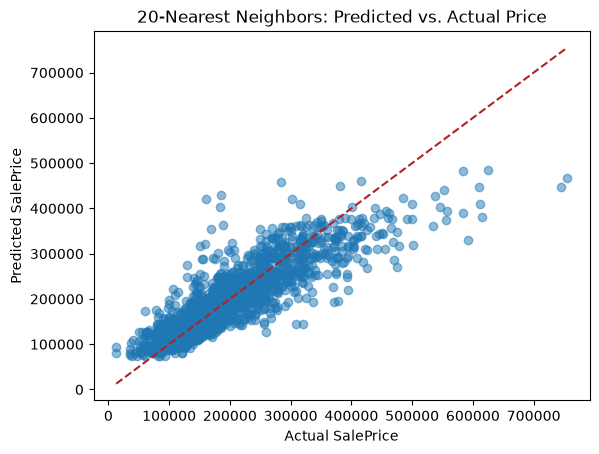

In [17]:
knn_20 = Pipeline([
    ("preprocessing", preprocessor),
    ("knn", KNeighborsRegressor(n_neighbors=20))
])

knn_20.fit(X, y)
predicted_price_20 = knn_20.predict(X)

plt.scatter(y, predicted_price_20, alpha=0.5)
limits = [min(y.min(), predicted_price_20.min()),
          max(y.max(), predicted_price_20.max())]
plt.plot(limits, limits, color="firebrick", linestyle="--")
plt.xlabel("Actual SalePrice")
plt.ylabel("Predicted SalePrice")
plt.title("20-Nearest Neighbors: Predicted vs. Actual Price")
plt.show()

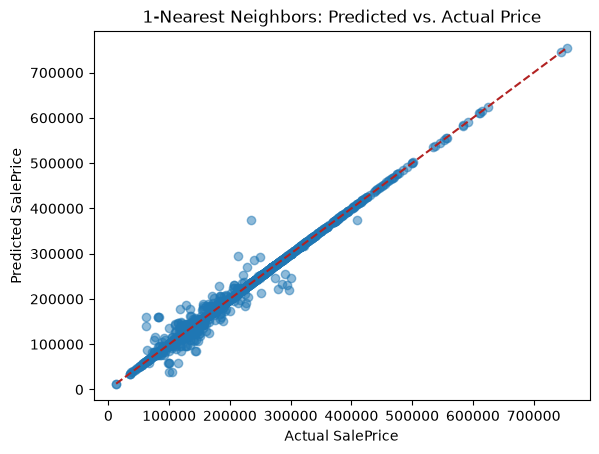

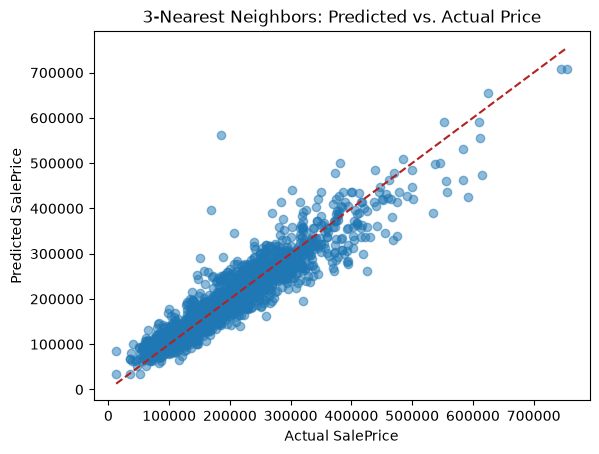

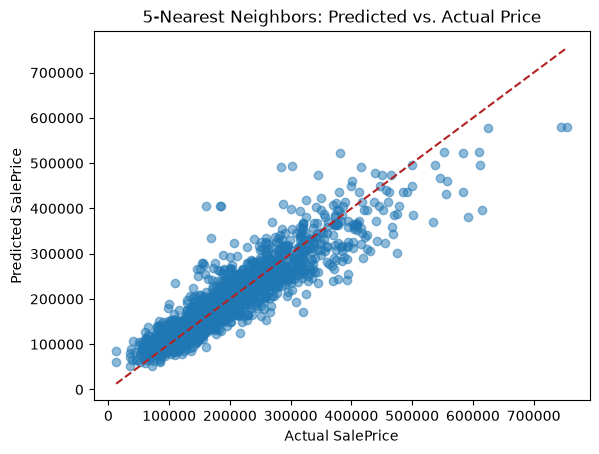

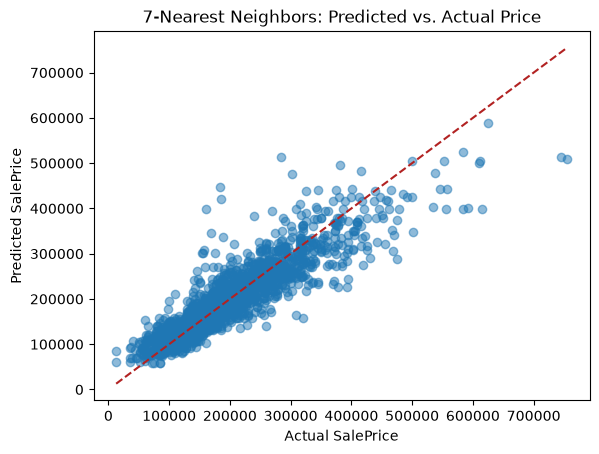

In [18]:
for k in [1, 3, 5, 7]:
    knn_model = Pipeline([
        ("preprocessing", preprocessor),
        ("knn", KNeighborsRegressor(n_neighbors=k))
    ])

    knn_model.fit(X, y)
    predicted_price = knn_model.predict(X)

    plt.scatter(y, predicted_price, alpha=0.5)
    limits = [min(y.min(), predicted_price.min()),
              max(y.max(), predicted_price.max())]
    plt.plot(limits, limits, color="firebrick", linestyle="--")
    plt.xlabel("Actual SalePrice")
    plt.ylabel("Predicted SalePrice")
    plt.title(f"{k}-Nearest Neighbors: Predicted vs. Actual Price")
    plt.show()

On these plots k = 1 looks the best because each home is its own nearest neighbor, so predictions are closes to the actual prices making the points very close to the diagonal line. However, this most likely overfits. 

13. Fit a regression decison tree that predicts the price (just **SalePrice**, not log) of a home using square footage (**Gr Liv Area**), number of bedrooms (**Bedroom AbvGr**), number of full bathrooms (**Full Bath**), number of half bathrooms (**Half Bath**), and **Neighborhood**. Use a max depth of 4. Use a pipeline and column transformers as needed. Plot and interpret the tree. Also, make a scatter plot of predicting price versus actual price.

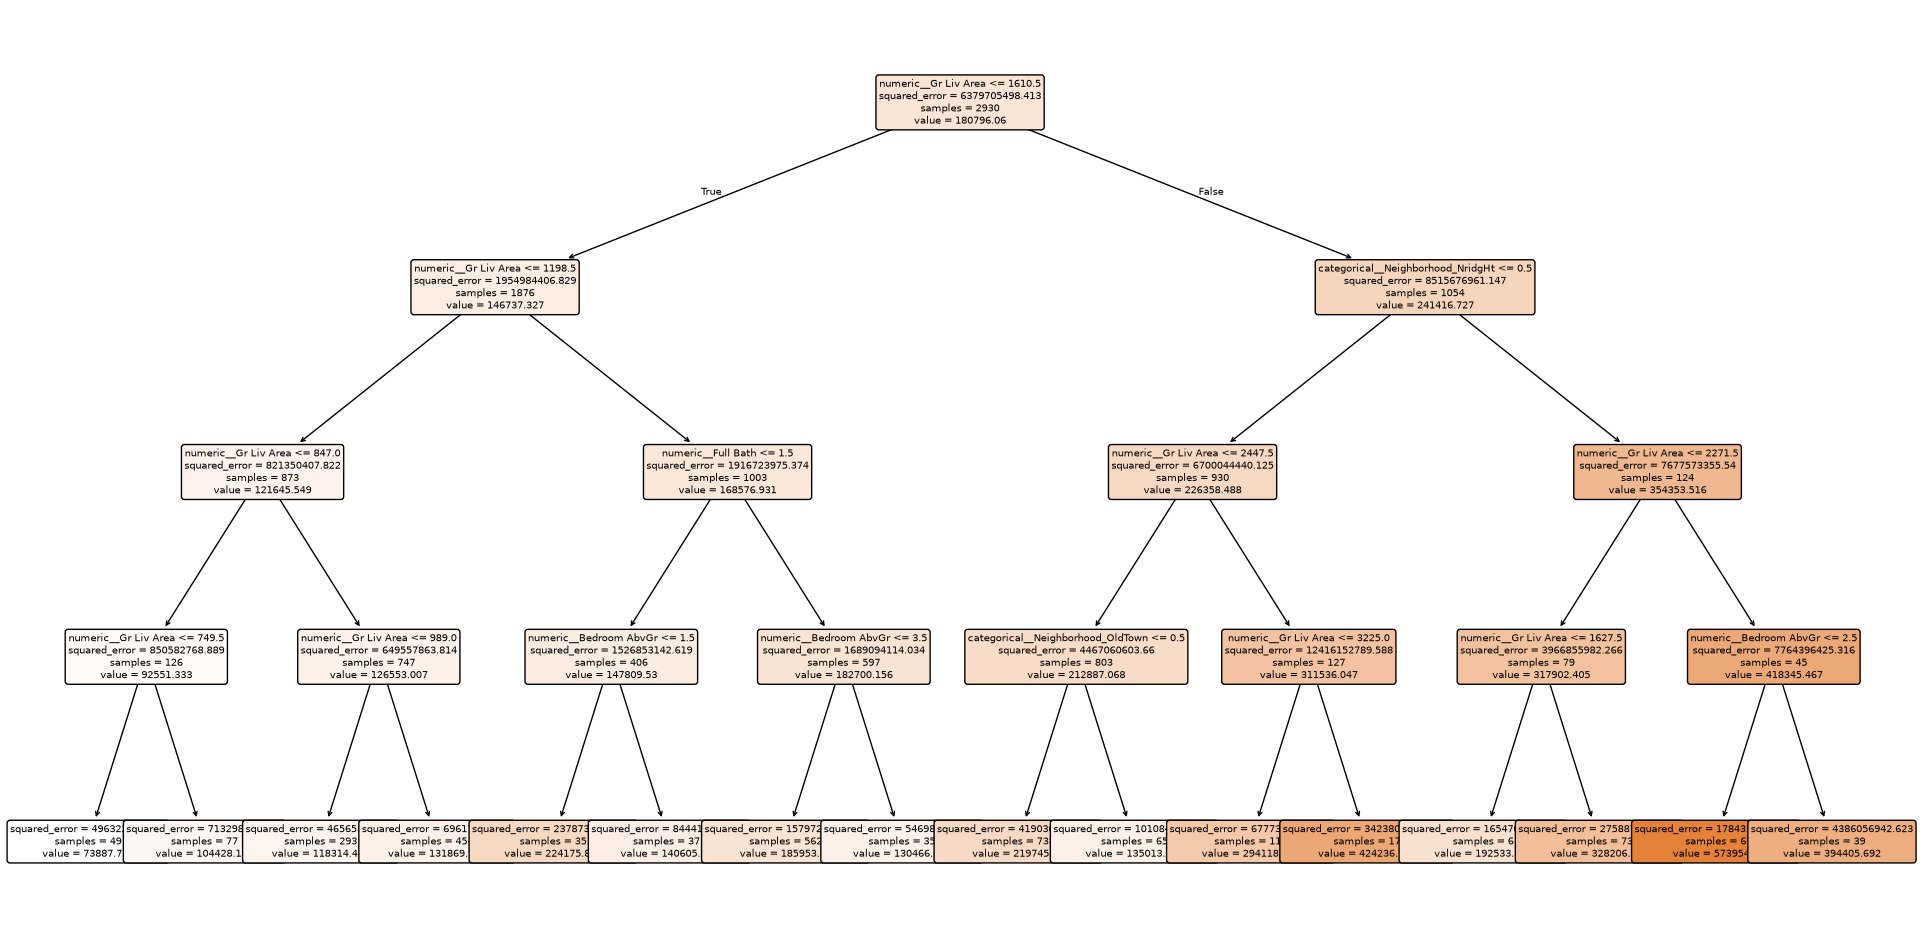

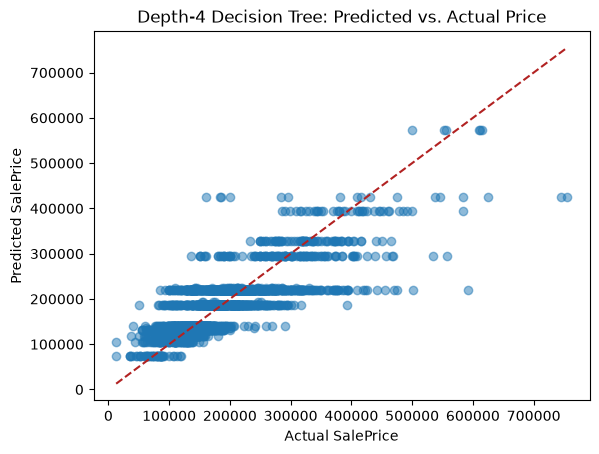

In [19]:
from sklearn.tree import DecisionTreeRegressor, plot_tree

tree_preprocessor = ColumnTransformer([
    ("numeric", "passthrough", numeric_features),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

tree_model = Pipeline([
    ("preprocessing", tree_preprocessor),
    ("tree", DecisionTreeRegressor(max_depth=4, random_state=5544))
])

tree_model.fit(X, y)
predicted_price_tree = tree_model.predict(X)

plt.figure(figsize=(24, 12))
plot_tree(
    tree_model.named_steps["tree"],
    feature_names=tree_model.named_steps["preprocessing"].get_feature_names_out(),
    filled=True,
    rounded=True,
    fontsize=7
)
plt.show()

plt.scatter(y, predicted_price_tree, alpha=0.5)
limits = [min(y.min(), predicted_price_tree.min()),
          max(y.max(), predicted_price_tree.max())]
plt.plot(limits, limits, color="firebrick", linestyle="--")
plt.xlabel("Actual SalePrice")
plt.ylabel("Predicted SalePrice")
plt.title("Depth-4 Decision Tree: Predicted vs. Actual Price")
plt.show()

The tree is interpreted by following a path from the top of the tree to each leaf. Each split narrows the homes into a group and the leaf's value is that group's predicted sale price. 

14. Repeat the previous part with different values of `max_depth`. What value of seems to be "best"? How are you deciding?

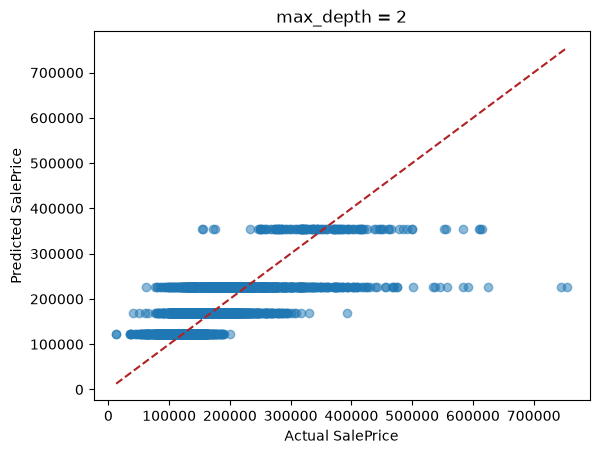

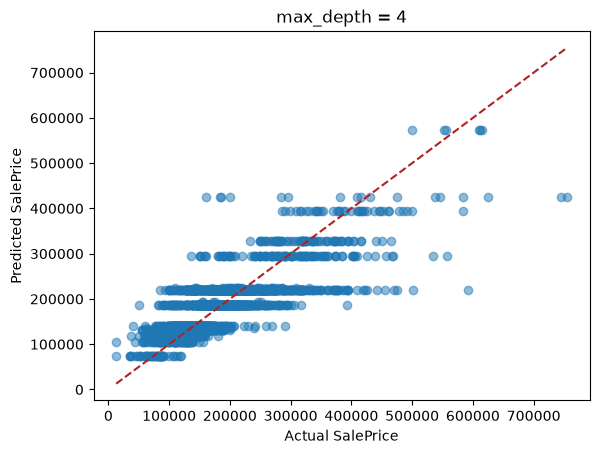

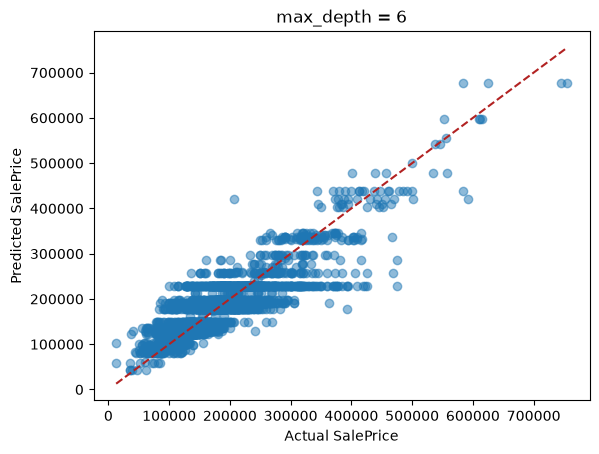

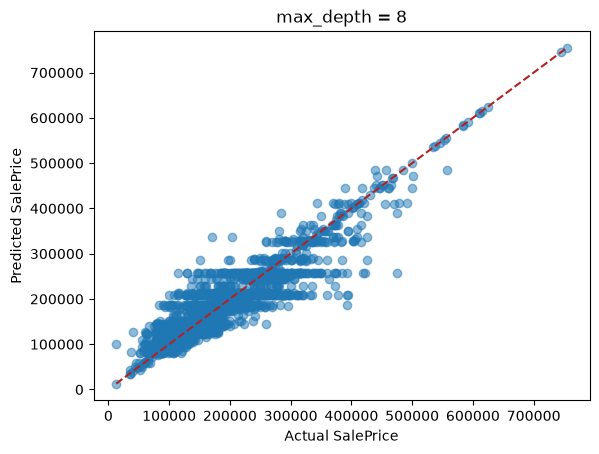

In [20]:
for depth in [2, 4, 6, 8]:
    tree_model = Pipeline([
        ("preprocessing", tree_preprocessor),
        ("tree", DecisionTreeRegressor(max_depth=depth, random_state=5544))
    ])

    tree_model.fit(X, y)
    predicted_price = tree_model.predict(X)

    plt.scatter(y, predicted_price, alpha=0.5)
    limits = [min(y.min(), predicted_price.min()),
              max(y.max(), predicted_price.max())]
    plt.plot(limits, limits, color="firebrick", linestyle="--")
    plt.title(f"max_depth = {depth}")
    plt.xlabel("Actual SalePrice")
    plt.ylabel("Predicted SalePrice")
    plt.show()

8 looks the best because the dots see the closest to the line and the least like a completely different shape. Deep trees can overfit, though. 